# Bài 7 — Kiểm tra chu trình trong DFS

Notebook khảo sát trực quan ba cách kiểm tra chu trình của DFS trên `open_maze.txt`. Mục tiêu là so sánh số vòng lặp, kích thước frontier và mức độ lặp lại trạng thái khi cùng dùng thứ tự hành động `N, E, S, W`.



# Code

Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).


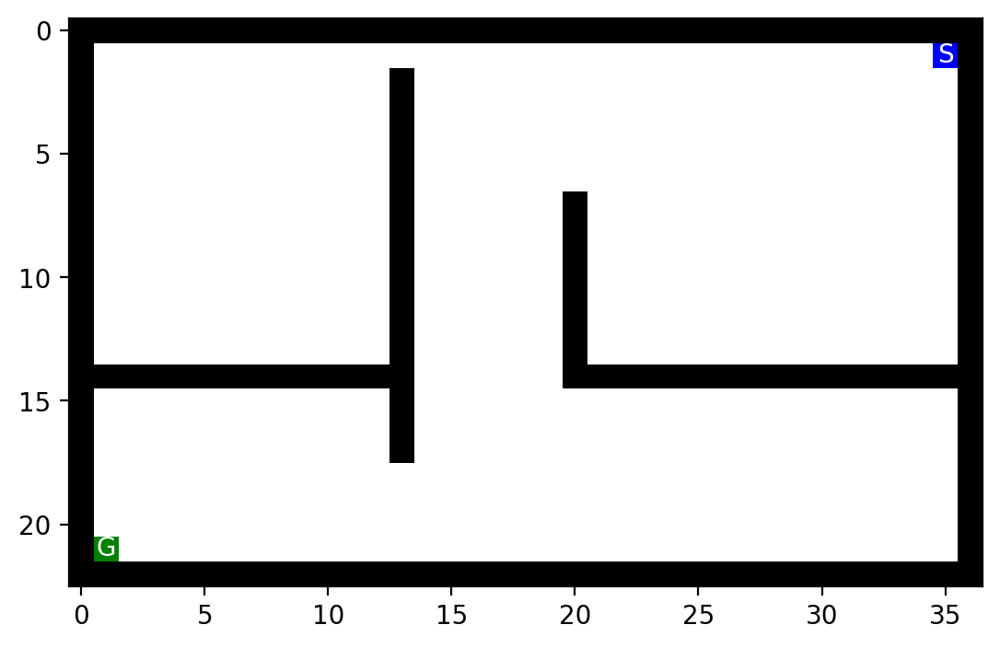

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np


#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

In [2]:
# Dùng module triển khai đi kèm repository thay cho file riêng không được công bố.
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import tree_search_solution as ts
ts = importlib.reload(ts)

# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)


## Phương án 1: Chỉ kiểm tra đường đi hiện tại

Không mở rộng node nếu trạng thái của nó đã xuất hiện trên đường từ gốc đến node hiện tại. Cơ chế hoạt động:

* Bước expand đưa mọi successor vào frontier.
* Khi lấy một node khỏi frontier, DFS kiểm tra trạng thái đó có trùng với một tổ tiên trên đường hiện tại hay không.
* Nếu trùng, node bị bỏ qua và DFS lấy node tiếp theo từ stack.

Cách này chặn chu trình trong một nhánh nhưng quản lý frontier chưa tốt: cùng một trạng thái vẫn có thể được nhiều nhánh thêm vào stack, khiến DFS quay lại khám phá một vùng nhiều lần.


In [3]:
%time result_path_only = ts.DFS(maze, vis=False, animation=True, max_tries=500, frontier_option=3)

ts.animate_maze(result_path_only)

CPU times: total: 31.2 ms
Wall time: 109 ms
No solution found.


Trong animation, vùng đã xét có thể trông như đã được phủ kín nhưng stack vẫn còn nhiều bản sao của các trạng thái trong vùng đó.

## Phương án 2: Kiểm tra đường đi và không thêm trạng thái đang có trong frontier

Mỗi trạng thái chỉ có tối đa một node đang chờ trong stack tại cùng một thời điểm. Tuy nhiên, sau khi node bị lấy khỏi stack, trạng thái đó có thể được nhánh khác thêm trở lại; do đó hiện tượng khám phá lặp vẫn chưa được loại bỏ hoàn toàn.

In [4]:
%time result_no_duplicate = ts.DFS(maze, animation=True, max_tries=500, frontier_option=2)

ts.animate_maze(result_no_duplicate)

CPU times: total: 31.2 ms
Wall time: 109 ms
Path length: 292
Reached squares: 527
Action sequence: ['S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'W', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'N', 'N', 'N', 'N', 'W', 'W', 'S', 'S', 'S', 'S', 'W', 'W', 'N', 'N', 'N', 'N', 'W', 'W', 'S', 'S', 'S', 'S', 'W', 'W', 'N', 'N', 'N', 'N', 'W', 'W', 

Quan sát các ô frontier màu cam: một số ô vẫn còn chờ sau khi DFS đã quay lui khỏi nhánh tương ứng. Chúng có thể làm DFS đi vào vùng cũ thêm lần nữa.


## Phương án 3: Kiểm tra đường đi và đưa trạng thái trùng lên đầu stack

Khi sinh ra một trạng thái đã có trong frontier, ta không tạo node thứ hai mà chuyển node đang chờ lên đầu stack. Vì DFS dùng LIFO, trạng thái đó sẽ được xử lý sớm, giúp dọn các entry liên quan đến nhánh hiện tại và giảm kích thước frontier.

In [4]:
%time result_move_to_top = ts.DFS(maze, vis=False, animation=True, max_tries=3000, frontier_option=1)

ts.animate_maze(result_move_to_top)

CPU times: total: 109 ms
Wall time: 249 ms
Path length: 66
Reached squares: 335
Action sequence: ['S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'N', 'N', 'N', 'N', 'N', 'N', 'W', 'W', 'W', 'S', 'W', 'S', 'W', 'S', 'W', 'S', 'W', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'S', 'W', 'S', 'W', 'W', 'S', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


# Tổng hợp thí nghiệm Bài 7

## So sánh ba phương án

Ba phương án dưới đây cùng chạy trên `open_maze`, cùng thứ tự sinh successor `NESW` và cùng ngân sách 3.000 lần lấy node khỏi stack. Animation phía trên chỉ dùng 500 lần lặp để tránh output quá lớn; bảng dưới đây mới là phép đo định lượng chính.

Các đại lượng được ghi nhận:

- **Số lần lặp**: số node được lấy khỏi stack để kiểm tra.
- **Frontier lớn nhất**: số node tối đa cùng tồn tại trong stack.
- **Frontier còn lại**: số node chưa xử lý khi thuật toán dừng.
- **Lấy lại trạng thái**: số lần pop một trạng thái đã từng được pop trước đó; đây là biểu hiện trực tiếp của việc khám phá lặp.
- **Gặp trùng trong frontier**: số lần sinh ra một trạng thái đang chờ sẵn trong stack.
- **Bỏ qua do chu trình**: số node bị loại vì trạng thái của nó đã nằm trên đường từ gốc đến node đó.


In [6]:
STRATEGIES = {
    '1. Chỉ kiểm tra đường hiện tại': 3,
    '2. Đường đi + không thêm trùng frontier': 2,
    '3. Đường đi + đưa trạng thái trùng lên đầu stack': 1,
}
COMPARISON_LIMIT = 3000
comparison_results = {}

for strategy_name, option in STRATEGIES.items():
    ts.set_order('NESW')
    comparison_results[strategy_name] = ts.DFS(
        maze, vis=False, animation=False,
        max_tries=COMPARISON_LIMIT, frontier_option=option
    )

comparison_table = pd.DataFrame([
    {
        'Phương án': name,
        'Kết quả': result['status'],
        'Chi phí lời giải': result['path_cost'],
        'Số lần lặp': result['iterations'],
        'Số node mở rộng': result['expanded'],
        'Frontier lớn nhất': result['max_frontier'],
        'Frontier còn lại': result['final_frontier'],
        'Lấy lại trạng thái': result['repeated_pops'],
        'Tỉ lệ lặp (%)': round(100 * result['repeated_pops'] / result['iterations'], 1),
        'Gặp trùng trong frontier': result['duplicate_encounters'],
        'Bỏ qua do chu trình': result['cycle_skips'],
    }
    for name, result in comparison_results.items()
])

display(comparison_table.style.hide(axis='index')
        .set_caption('So sánh ba phương án cycle checking trên open_maze'))


Phương án,Kết quả,Chi phí lời giải,Số lần lặp,Số node mở rộng,Frontier lớn nhất,Frontier còn lại,Lấy lại trạng thái,Tỉ lệ lặp (%),Gặp trùng trong frontier,Bỏ qua do chu trình
1. Chỉ kiểm tra đường hiện tại,LIMIT,nan,3000,1172,1025,1000,2404,80.100000,2815,1828
2. Đường đi + không thêm trùng frontier,FOUND,292.000000,467,293,354,352,173,37.000000,236,173
3. Đường đi + đưa trạng thái trùng lên đầu stack,FOUND,66.000000,2090,1376,276,275,1812,86.700000,2696,713


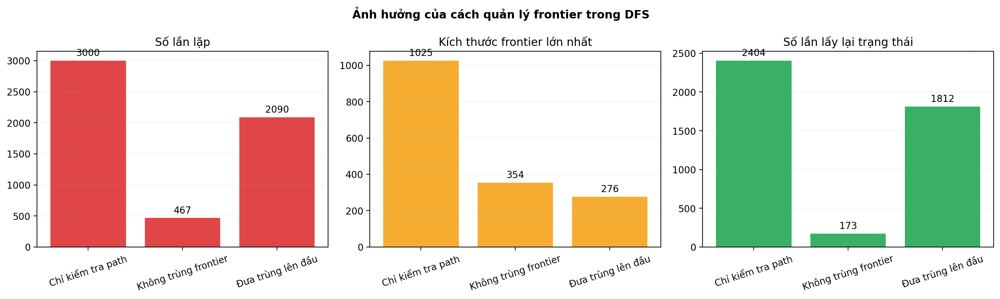

In [7]:
# Ba biểu đồ dùng chung thứ tự phương án và cùng thang đo theo từng chỉ số.
short_labels = ['Chỉ kiểm tra path', 'Không trùng frontier', 'Đưa trùng lên đầu']
colors = ['#dc2626', '#f59e0b', '#16a34a']
metrics = [
    ('Số lần lặp', 'Số lần lặp'),
    ('Frontier lớn nhất', 'Kích thước frontier lớn nhất'),
    ('Lấy lại trạng thái', 'Số lần lấy lại trạng thái'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for axis, (column, title), color in zip(axes, metrics, colors):
    bars = axis.bar(short_labels, comparison_table[column], color=color, alpha=0.85)
    axis.bar_label(bars, padding=3)
    axis.set_title(title)
    axis.tick_params(axis='x', rotation=18)
    axis.grid(axis='y', linestyle=':', alpha=0.35)
fig.suptitle('Ảnh hưởng của cách quản lý frontier trong DFS', fontweight='bold')
fig.tight_layout()
plt.show()


## Phân tích và kết luận

### 1. Chỉ kiểm tra trạng thái trên đường đi hiện tại

DFS kiểm tra xem ô đang xét có nằm trên đường từ điểm bắt đầu đến node cha hay không. Ví dụ, đường S → A → B → A quay lại ô A nên lần xuất hiện thứ hai của A bị bỏ qua. Tuy nhiên, hai nhánh khác nhau vẫn có thể đi đến cùng một ô và đưa hai node của ô đó vào frontier. Kiểm tra đường đi không loại được trường hợp này.

Trong thí nghiệm, phương án 1 dừng sau 3.000 lần lặp mà chưa tìm thấy đích. Frontier lớn nhất là 1.025 node, có 2.404 lần lấy ra một trạng thái đã từng được lấy trước đó. Các số liệu cho thấy DFS xét lại nhiều ô và giữ nhiều node chờ xử lý. Kết quả LIMIT chỉ có nghĩa là đã đạt giới hạn 3.000 lần lặp, chưa đủ để kết luận thuật toán lặp vô hạn hoặc mê cung không có lời giải.

### 2. Kiểm tra đường đi và không thêm trạng thái đã có trong frontier

Ngoài kiểm tra đường đi, DFS kiểm tra cả các node đang chờ trong frontier. Nếu ô C đã có trong stack thì khi một nhánh khác sinh ra C, thuật toán không thêm node mới. Nhờ vậy, cùng một trạng thái không có nhiều node chờ xử lý đồng thời.

Tuy nhiên, sau khi node C được lấy khỏi stack, một nhánh khác vẫn có thể thêm C trở lại. Vì vậy phương án này giảm trùng trong frontier nhưng chưa loại hết việc xét lại trạng thái.

Phương án 2 tìm thấy đích sau 467 lần lặp, frontier lớn nhất là 354 node và có 173 lần lấy lại trạng thái. Đây là phương án có ít lần lặp và ít lần lấy lại trạng thái nhất trong thí nghiệm. Đường tìm được dài 292 bước: DFS gặp đích sớm trong quá trình tìm kiếm nhưng đường dẫn đến đích vẫn có thể dài.

### 3. Kiểm tra đường đi và đưa trạng thái trùng lên đầu stack

Nếu một trạng thái đã có trong frontier, thuật toán chuyển node đang chờ lên đầu stack thay vì thêm bản sao hoặc giữ nguyên vị trí của nó. Vì DFS lấy node ở đầu stack trước, trạng thái đó được xét sớm hơn. Việc này thay đổi thứ tự duyệt các nhánh.

Phương án 3 tìm thấy đích sau 2.090 lần lặp, frontier lớn nhất là 276 node và đường đi dài 66 bước. So với phương án 2, frontier nhỏ hơn và đường đi ngắn hơn, nhưng số lần lặp nhiều hơn. Có 1.812 lần lấy lại trạng thái, nên việc chuyển node lên đầu stack không loại hết hiện tượng lặp.

Kết quả này cho thấy phương án 3 có lợi về kích thước frontier trong lần chạy hiện tại, nhưng không nhanh hơn phương án 2 nếu so bằng số lần lặp. Đường 66 bước cũng chưa phải đường tối ưu, vì BFS tìm được đường 54 bước trên cùng mê cung.

### Kết luận chung

Trên open_maze với thứ tự NESW, phương án 1 có frontier lớn nhất và chưa tìm được đích trong 3.000 lần lặp. Phương án 2 tìm thấy đích với ít lần lặp nhất nhưng cho đường đi dài nhất trong hai phương án tìm được lời giải. Phương án 3 có frontier cực đại nhỏ nhất và đường đi ngắn hơn phương án 2, nhưng phải xét nhiều node hơn.

Kiểm tra đường đi giúp ngăn việc quay lại một ô trong cùng nhánh; kiểm tra frontier giúp hạn chế các node trùng đang chờ xử lý. Hai việc này không bảo đảm rằng một trạng thái chỉ được xét một lần. Cả ba cách vẫn dùng DFS nên không bảo đảm đường ngắn nhất. Những nhận xét trên dựa vào đúng mê cung và thứ tự duyệt của thí nghiệm; đổi thứ tự hành động có thể làm các số liệu thay đổi.

